# 03 — Comparative analysis: Q-Learning vs DQN

All numbers come from `results/comparison/*.csv`, produced by `python -m scripts.analyze`.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS = ROOT / "results"

In [2]:
summary = pd.read_csv(RESULTS / "comparison" / "summary.csv").set_index("run_name")
summary.T

run_name,dqn,tabular_b6_primary,tabular_b10_primary,tabular_b20_primary,tabular_b10_tight,tabular_b6_primary_eps50k,tabular_b10_primary_eps50k,tabular_b20_primary_eps50k,tabular_b10_tight_eps50k
n_seeds,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000,5.000
final_mean,390.776,213.584,357.626,290.536,317.778,203.140,179.984,158.394,250.690
final_ci95_half_width,257.209,37.655,165.211,77.837,68.119,70.743,68.026,62.449,147.689
final_std_across_seeds,207.182,30.331,133.078,62.697,54.870,56.983,54.795,50.303,118.963
final_min,24.180,186.340,139.840,206.480,259.810,144.660,87.250,109.120,91.330
final_max,500.000,251.500,491.330,377.770,389.580,272.660,222.640,212.010,410.980
seeds_final_success,3.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000
seeds_reaching_threshold_ever,4.000,0.000,3.000,0.000,2.000,0.000,0.000,0.000,1.000
median_steps_to_threshold,117500.000,NaN,160000.000,NaN,145000.000,NaN,NaN,NaN,180000.000
seeds_sustained_threshold,4.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,0.000


## Learning curves (mean ± 95% CI across 5 seeds)

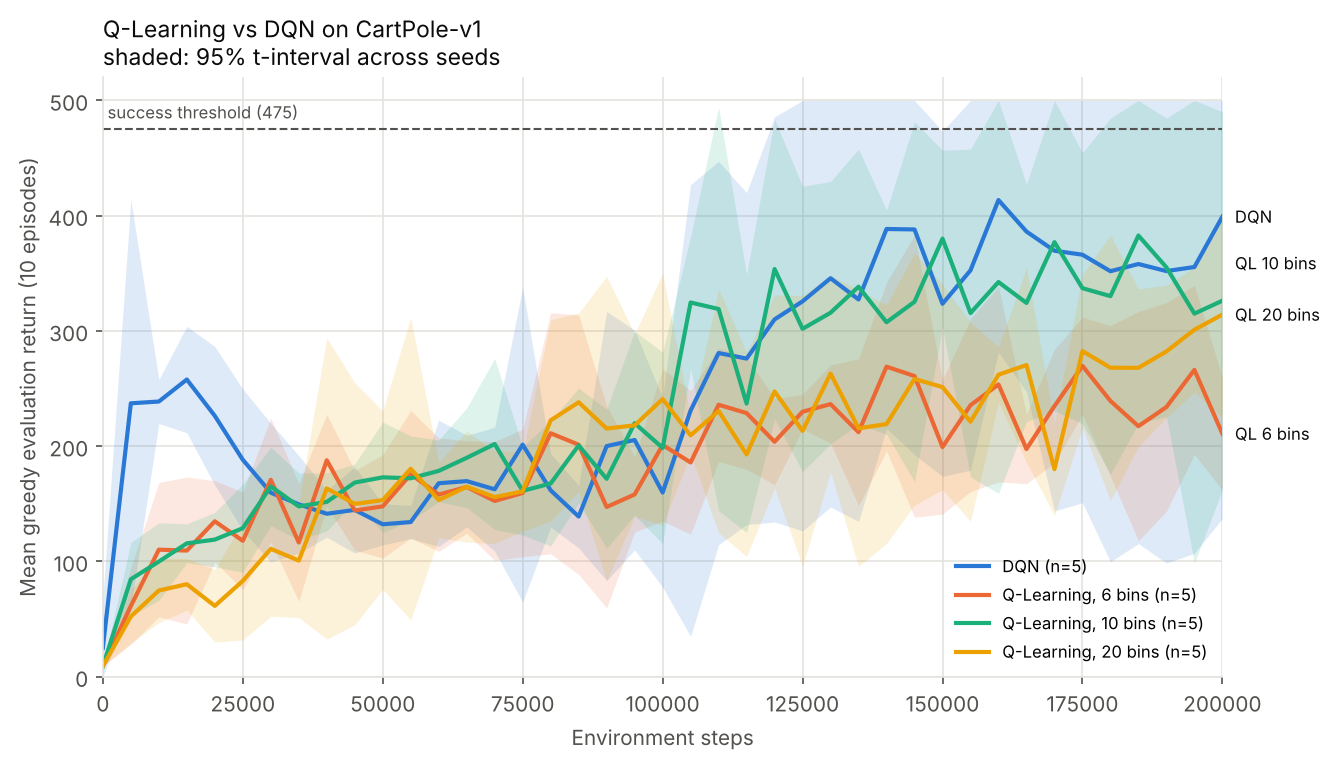

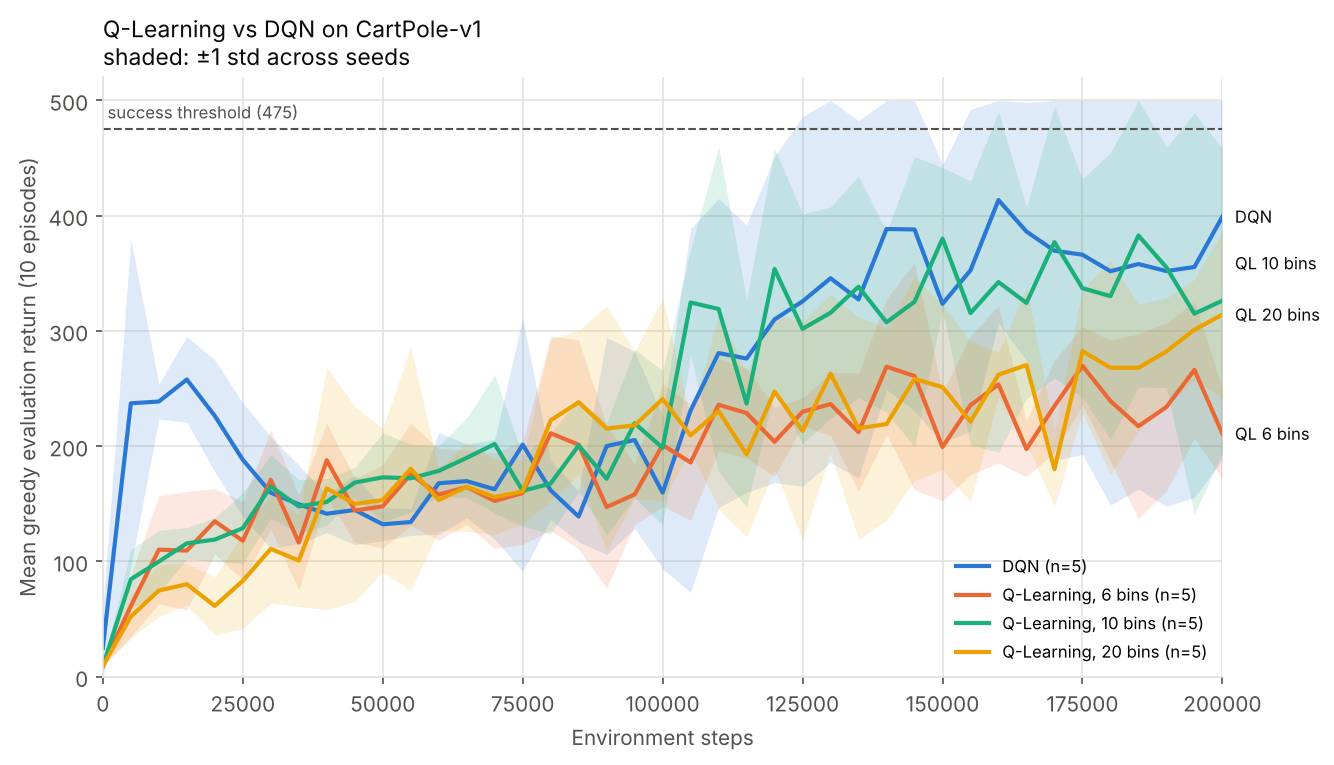

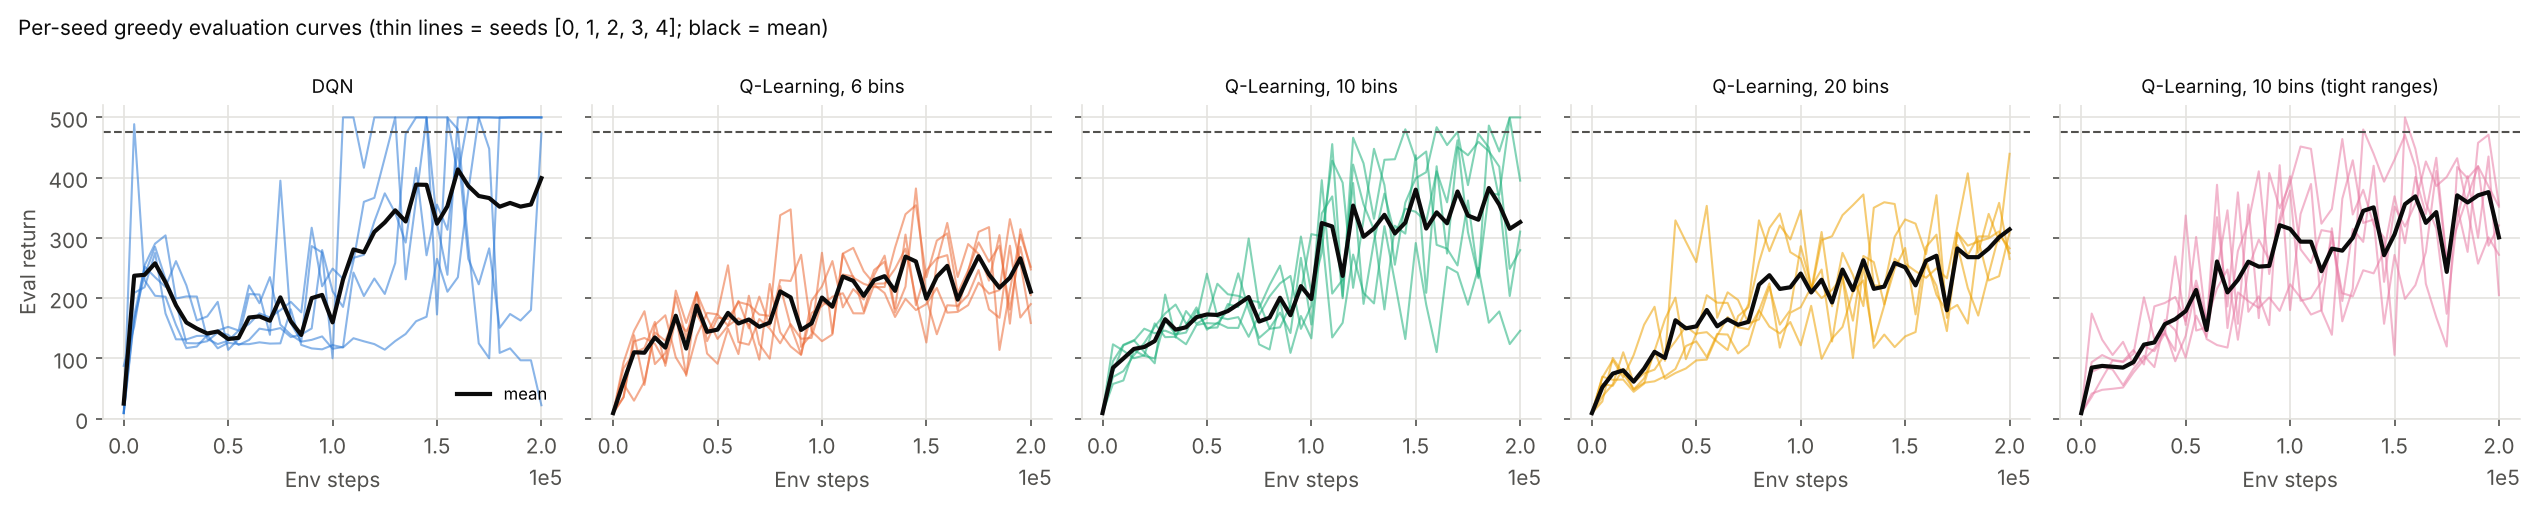

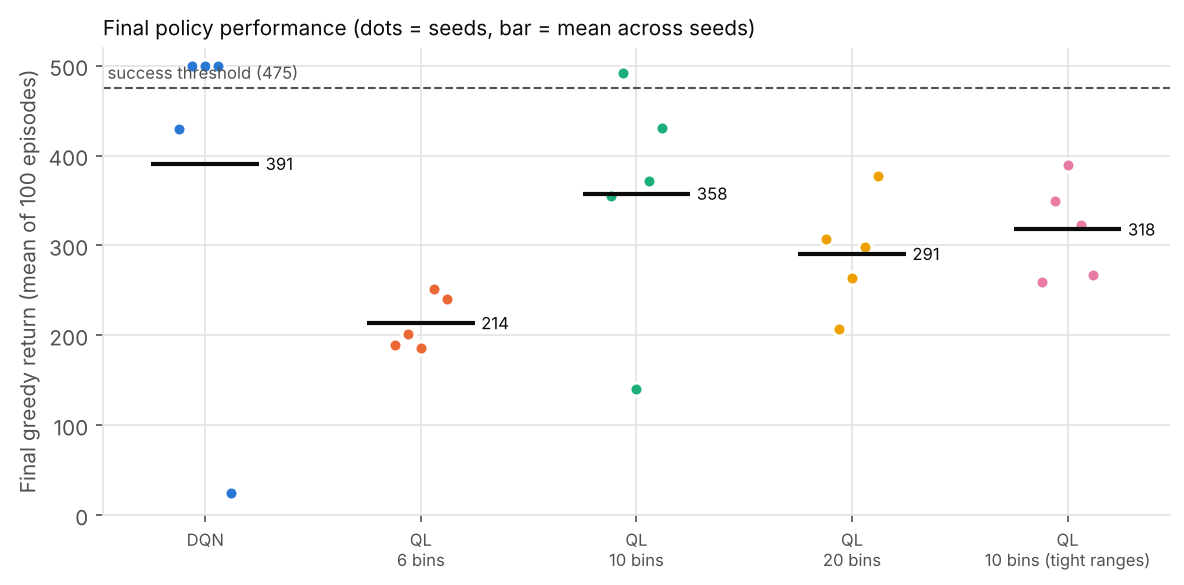

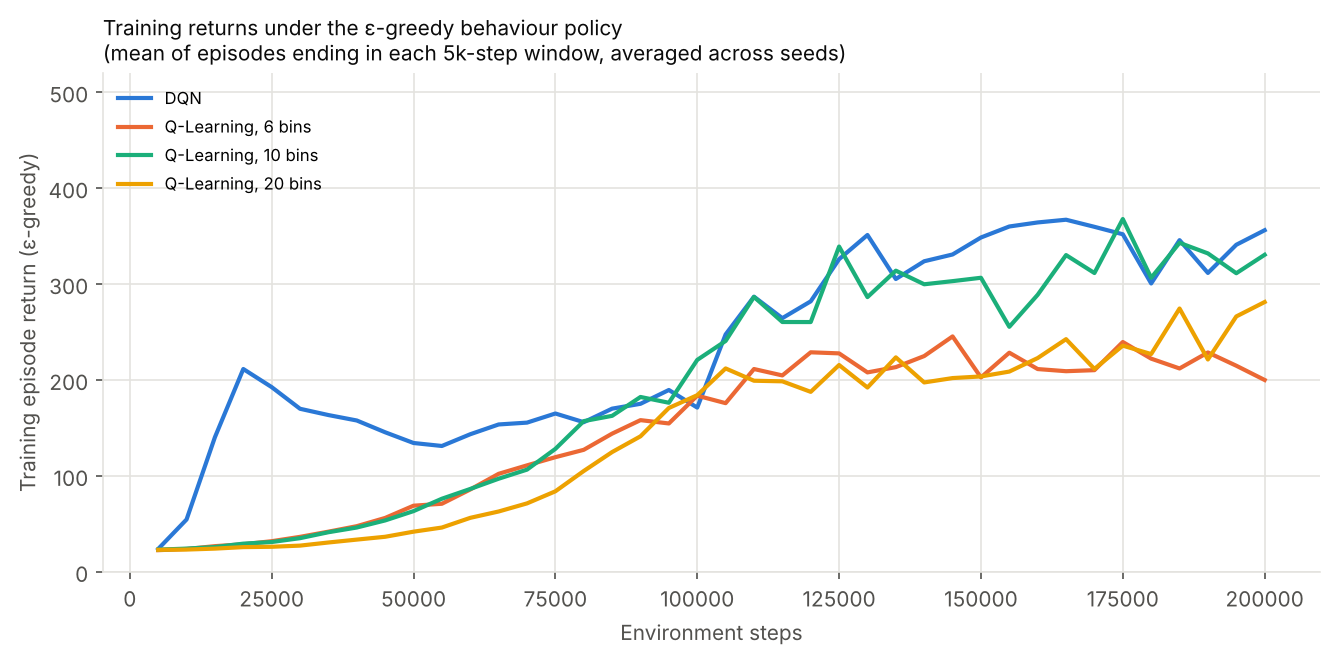

In [3]:
for f in ["learning_curves_ci95.png", "learning_curves_std.png", "per_seed_curves.png", "final_returns.png", "training_returns.png"]:
    display(Image(RESULTS / "comparison" / "figures" / f))

## Compact comparison table

In [4]:
cols = {"final_mean": "final return (mean)", "final_ci95_half_width": "±95% CI", "final_std_across_seeds": "std across seeds",
        "seeds_final_success": "seeds ≥475 (final)", "seeds_reaching_threshold_ever": "seeds ≥475 (any checkpoint)",
        "median_steps_to_threshold": "median steps to 475", "mean_eval_over_training": "mean eval over training (AUC)",
        "post_success_drops_total": "drops >100 after success", "train_time_s_mean": "train time (s)"}
summary[list(cols)].rename(columns=cols)

,final return (mean),±95% CI,std across seeds,seeds ≥475 (final),seeds ≥475 (any checkpoint),median steps to 475,mean eval over training (AUC),drops >100 after success,train time (s)
run_name,,,,,,,,,
dqn,390.776,257.209,207.182,3,4,117500.000,256.197,7,351.672
tabular_b6_primary,213.584,37.655,30.331,0,0,NaN,186.829,0,14.487
tabular_b10_primary,357.626,165.211,133.078,1,3,160000.000,239.871,4,14.640
tabular_b20_primary,290.536,77.837,62.697,0,0,NaN,193.656,0,14.714
tabular_b10_tight,317.778,68.119,54.870,0,2,145000.000,244.888,5,14.187
tabular_b6_primary_eps50k,203.140,70.743,56.983,0,0,NaN,163.805,0,15.634
tabular_b10_primary_eps50k,179.984,68.026,54.795,0,0,NaN,161.148,0,15.883
tabular_b20_primary_eps50k,158.394,62.449,50.303,0,0,NaN,111.916,0,15.647
tabular_b10_tight_eps50k,250.690,147.689,118.963,0,1,180000.000,203.192,1,15.592
